# Continuous LunarLander — SAC

## Task description

**Task.** A lander starts near the top of the screen with a random initial push and must touch down gently on the landing pad at the center, on randomly generated terrain. It has to control its horizontal and vertical motion and its tilt, avoid crashing, and come to rest. Wind is disabled; gravity, engine rules, and the reward are fixed.

**State and observation.** The simulator state includes the lander's position, velocity, angle, angular velocity, leg contacts, and the terrain, plus the filtered engine command $u_{t-1}$ when command lag is active. The policy receives a 10-dimensional observation:

$$o_t=\left[x_t,\ y_t,\ \dot x_t,\ \dot y_t,\ \phi_t,\ \dot\phi_t,\ c_t^{\mathrm L},\ c_t^{\mathrm R},\ u_t^{\mathrm{main}},\ u_t^{\mathrm{side}}\right],$$

the eight standard Gymnasium values (normalized position and velocity, body angle $\phi$ and angular velocity, and two leg-contact flags) plus the two engine commands actually applied. The command entries are included in both conditions, so the policy can see the filter's memory.

**Action and engine-command lag.** The action $a_t=(a_t^{\mathrm{main}},a_t^{\mathrm{side}})\in[-1,1]^2$ is the requested engine command. It passes through a first-order filter before reaching the engines:

$$u_t=u_{t-1}+\beta\,(a_t-u_{t-1}),\qquad \beta=1-e^{-\Delta t/\tau},\qquad \Delta t=0.02\ \text{s}.$$

With $\tau=0$ ($\beta=1$) this is the standard environment. With $\tau=0.1$ s, a command change reaches 63% of its target after 0.1 s and 95% after about 0.3 s. The experiment compares $\tau=0$ and $\tau=0.1$ s.

**Engines.** The main engine fires only when $u^{\mathrm{main}}>0$, with power $(u^{\mathrm{main}}+1)/2\in[0.5,1]$. The side engines fire only when $|u^{\mathrm{side}}|>0.5$, with power $|u^{\mathrm{side}}|$; the sign selects left or right. Because of these thresholds, the lag also delays when an engine switches on or off.

**Reward.** The reward is Gymnasium's built-in reward, unchanged. Each step pays the change in a shaping potential that favors being near the pad, slow, level, and with legs down:

$$r_t=\Phi_{t+1}-\Phi_t-0.3\,p_t^{\mathrm{main}}-0.03\,p_t^{\mathrm{side}},\qquad
\Phi=-100\sqrt{x^2+y^2}-100\sqrt{\dot x^2+\dot y^2}-100\,|\phi|+10\,(c^{\mathrm L}+c^{\mathrm R}).$$

The episode ends with −100 for a crash or leaving the screen horizontally, and +100 when the lander comes to rest.

**Outcomes.** An episode ends in **landed** (the lander comes to rest), **failed** (crash or out of bounds), or **timeout** (1000 steps, treated as truncation rather than failure). "Landed" is the simulator's definition: it does not require touching down on the pad or below a set speed. A return of at least 200 is reported separately as the conventional "solved" threshold.

Full details: [docs/lunarlander.md](../docs/lunarlander.md).

## 1. Environment setup

Mount Google Drive, locate the project, install dependencies, and register the package import path. Local execution uses the project root or its `notebooks/` directory.

In [1]:
from pathlib import Path
import sys

# Project location.
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/rl_examples")  # Google Drive project path.
else:
    PROJECT = Path.cwd()
    if not (PROJECT / "pyproject.toml").exists():
        PROJECT = PROJECT.parent

assert (PROJECT / "pyproject.toml").exists(), f"Project not found: {PROJECT}"
%pip -q install "swig>=4.2,<5"
%pip -q install -e "{PROJECT}"

assert (PROJECT / "rl_examples" / "__init__.py").exists(), "Python package directory missing"
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
import importlib
importlib.invalidate_caches()

Mounted at /content/drive
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for rl-examples (pyproject.toml) ... done


## 2. Imports

Load configuration, training, evaluation, simulation, and plotting functions. Limit PyTorch CPU execution to two threads.

In [2]:
import os
os.environ.setdefault("SDL_VIDEODRIVER", "dummy")
from dataclasses import replace
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Video
from rl_examples.configs.settings import NavigationConfig, LanderConfig, SACConfig, PPOConfig, TrainingConfig
from rl_examples.configs.smoke import smoke_settings
from rl_examples.training.runner import run_experiment
from rl_examples.evaluation.comparison import compare_runs
from rl_examples.evaluation.metrics import paired_efficiency
from rl_examples.simulation.examples import simulate_runs
from rl_examples.visualization.plots import plot_learning_curves, plot_trajectories
from rl_examples.utils.labels import run_labels, format_results

torch.set_num_threads(2)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 3. Experiment configuration

Set environment parameters, algorithm hyperparameters, training budgets, and scenario seeds. `SMOKE_ONLY=True` runs a short pipeline check; `False` enables full training. `MODE="load"` reads completed runs with matching settings. Results are stored under `outputs/`.

In [4]:
SMOKE_ONLY = False  # True: pipeline check; False: full training.
MODE = "train"     # "train" or "load".
RUN_NAME = "lunarlander_sac_v1"  # Experiment identifier.
RUN_HELD_OUT_TEST = False

conditions = {
    "standard": LanderConfig(tau_seconds=0.0),
    "command_lag": LanderConfig(tau_seconds=0.10),
}
stages = None
agent_config = SACConfig(buffer_size=300_000, learning_starts=5000)

training_config = TrainingConfig(
    steps_per_stage=250_000, eval_every=10_000, seed=42,
    early_stopping=True, min_steps=100_000, patience=10, min_delta=2.0,
    validation_a=tuple(range(20000, 20020)),
    validation_b=tuple(range(21000, 21020)),
    test_seeds=tuple(range(30000, 30100)),
)

if SMOKE_ONLY:
    conditions, agent_config, training_config, stages = smoke_settings(
        conditions, agent_config, training_config, stages)
OUTPUT = PROJECT / "outputs" / (RUN_NAME + ("_smoke" if SMOKE_ONLY else ""))
print(OUTPUT)

/content/drive/MyDrive/rl_examples/outputs/lunarlander_sac_v1


## 4. Training

Train an independent policy for each condition and evaluate after each training interval. Validation A tracks performance; validation B selects the checkpoint. Training stops early when validation B return has not improved by at least `min_delta` for `patience` consecutive evaluations after `min_steps`.

In [5]:
runs = run_experiment(conditions, agent_config, training_config, OUTPUT, stages=stages, mode=MODE)

<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type swigvarlink has no __module__ attribute
/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(

SAC | engine lag = 0 s | 10,000 steps | B success=0% | return=-149.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


SAC | engine lag = 0 s | 20,000 steps | B success=0% | return=-57.3


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


SAC | engine lag = 0 s | 30,000 steps | B success=0% | return=-133.9


... (91 outputs left out)

SAC | engine lag = 0.1 s | 240,000 steps | B success=100% | return=264.4


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


SAC | engine lag = 0.1 s | 250,000 steps | B success=100% | return=271.4


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 5. Learning curves

Plot exploratory training returns and deterministic validation returns and landing rates.

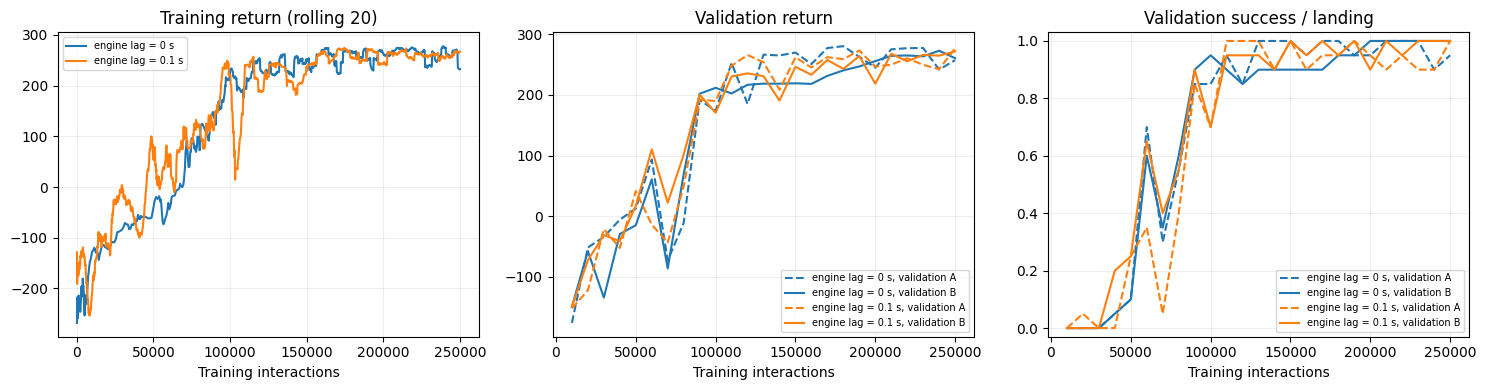

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [6]:
labels = run_labels(runs)
fig = plot_learning_curves(runs)
fig.savefig(OUTPUT / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Checkpoint validation

Compare selected and final checkpoints on validation B. Report efficiency on scenarios completed successfully by both selected policies. These selection-panel scores are not held-out test estimates.

In [7]:
summary, episodes = compare_runs(runs, training_config.validation_b)
display(format_results(summary, labels))
paired = paired_efficiency(episodes[episodes.checkpoint == "best"])
display(format_results(paired, labels))
summary.to_csv(OUTPUT / "validation_summary.csv", index=False)

,condition,checkpoint,checkpoint_steps,episodes,mean_return,success_rate,failed_rate,timeout_rate,successful_mean_steps,successful_mean_main_power_seconds,successful_mean_side_power_seconds
0,engine lag = 0 s,best,240000,20,272.552,1.0,0.0,0.0,209.85,1.785,0.666
1,engine lag = 0 s,final,250000,20,260.164,1.0,0.0,0.0,219.05,1.855,1.034
2,engine lag = 0.1 s,best,250000,20,271.383,1.0,0.0,0.0,234.80,2.007,0.374
3,engine lag = 0.1 s,final,250000,20,271.383,1.0,0.0,0.0,234.80,2.007,0.374


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,condition,common_successes,mean_steps,mean_main_power_seconds,mean_side_power_seconds
0,engine lag = 0.1 s,20,234.80,2.007,0.374
1,engine lag = 0 s,20,209.85,1.785,0.666


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 7. Trajectory comparison

Simulate the selected policies on three fixed validation scenarios. Rows correspond to scenario seeds; columns correspond to conditions. Each panel reports the episode outcome.

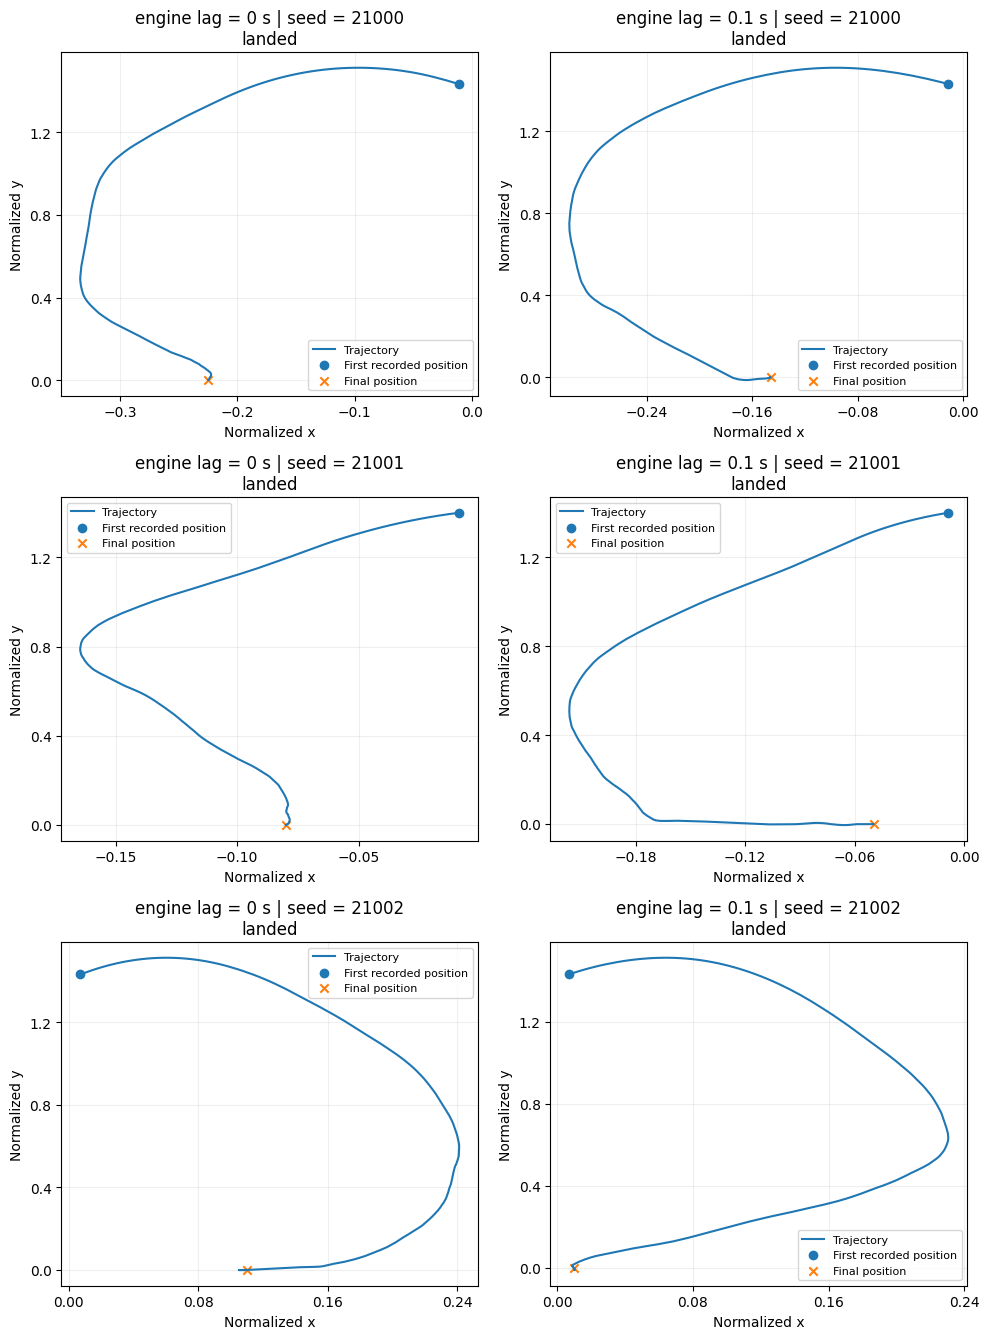

In [8]:
SCENARIO_SEEDS = (21000, 21001, 21002)
rollouts = simulate_runs(runs, seeds=SCENARIO_SEEDS)
fig = plot_trajectories(rollouts)
fig.savefig(OUTPUT / "trajectories.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Video export

Export selected-policy rollouts as MP4 files with PNG previews and JSON run metadata. Enable after full training. Navigation is sampled once per high-level action (2 fps); LunarLander is recorded at 50 fps.

In [9]:
RECORD_VIDEOS = True
VIDEO_SEEDS = (21000, 21001)
if RECORD_VIDEOS:
    if SMOKE_ONLY:
        raise ValueError("Video demonstrations require SMOKE_ONLY=False and completed training")
    videos = simulate_runs(runs, seeds=VIDEO_SEEDS, video_dir=OUTPUT / "videos")
    for condition, scenarios in videos.items():
        for seed, result in scenarios.items():
            print(f"{labels[condition]} | seed = {seed} | {result['metrics']['outcome']}")
            display(Video(str(result["video_path"]), embed=True))

engine lag = 0 s | seed = 21000 | landed


engine lag = 0 s | seed = 21001 | landed


engine lag = 0.1 s | seed = 21000 | landed


engine lag = 0.1 s | seed = 21001 | landed


## 9. Held-out evaluation

Evaluate selected checkpoints on reserved test scenarios after fixing the experiment settings. Report outcomes and paired efficiency without further checkpoint selection.

In [ ]:
if RUN_HELD_OUT_TEST:
    if SMOKE_ONLY:
        raise ValueError("Held-out evaluation requires full training")
    test_summary, test_episodes = compare_runs(
        runs, training_config.test_seeds, split="test", checkpoints=("best",))
    display(format_results(test_summary, labels))
    display(format_results(paired_efficiency(test_episodes), labels))
    test_summary.to_csv(OUTPUT / "test_summary.csv", index=False)
else:
    print("Held-out evaluation disabled.")